In [5]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator

from typing import Union, List

import frb_functions

In [11]:
def waterfaller_maker(burst, DM, t_downsamp=1, f_downsamp=1, dededisp=None):
    
    #Define the figure
    fig5 = plt.figure(figsize=(10,10))
    
    #Width 0.1 is for the hidden axes
    widths = [1]
    heights = [1, 2.5]
    spec5 = fig5.add_gridspec(ncols=1, nrows=2, width_ratios=widths, height_ratios=heights,\
                              wspace=0.25, hspace=0.0)

    ###################################
    burst = your.Your(burst_list[0])

    header_dict = frb_functions.your_header_to_dict(burst)

    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = int(header_dict["fmin"])
    fmax = int(header_dict["fmax"])
    extent_b = [tmin, tmax, fmin/1000, fmax/1000]

    offset = 5.1953
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst,nstart=0, nsamp=nbins, npoln=1)

    freqs = header_dict["freqs"] # in Mhz

    if dededisp != None:
        print(f"de-de-dispersing to DM zero using {dededisp} pc/cc")
        d = frb_functions.dedisperse(d,dededisp,freqs,tsamp)
        
    dm_dedisp = DM
    print(f"de-dispersing to {dm_dedisp} pc/cc")
    stokes_i = frb_functions.dedisperse(d,dm_dedisp,freqs,tsamp)

    print(f"Correcting for the bandpass")
    stokes_i = frb_functions.correct_bandpass(stokes_i)

    downsamp_t = t_downsamp
    downsamp_f = f_downsamp
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Masking Subband edges
    print(f"Masking")
    nchans = header_dict["nchans"]
    bw = header_dict["bw"] * -1
    # subband_edges_arr = frb_functions.get_subband_edges(bandwidth=bw, n_chan=nchans)
    
    simple_mask = np.arange(0,1)
    stokes_i = frb_functions.mask_array(stokes_i, simple_mask)
                                        
    new_quantiles = np.nanpercentile(stokes_i.compressed(), (1.0, 99))
    
    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof)
    
    ax2 = fig5.add_subplot(spec5[1, 0]) 
    ax2.imshow(stokes_i, aspect='auto', interpolation='None',\
          extent=extent_b, vmin=new_quantiles[0], vmax=new_quantiles[1])

    window_ms = 50
    ax2.set_xlim(-window_ms,window_ms)
    ax2.set_ylabel('Frequency (GHz)',size=25)
    ax2.set_xlabel('Time (ms)',size=25)
    ax2.yaxis.set_major_locator(ticker.LinearLocator(5))
    ax2.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    
    ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax2)
    ax1.set_ylabel('Intensity (arb.)',size=15,labelpad=20)
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-post', color='black')

    # ax1.text(0.96, 0.93, "Westerbork RT-1", transform=ax1.transAxes, fontsize=24, va='top', ha='right')
    # #ax1.text(-28,12, f"DM = 219.37" + r" pc cm$^{-3}$", fontsize=18)
    
    #Ticks on the SN-
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0,int(maxSN/2),int(maxSN)])
    
    ax1.set_yticks(np.array([]))
    #ax1.yaxis.set_minor_locator(ticker.LinearLocator(3))
    #ax1.set_ylim(-5,maxSN+2)

    ax1.text(0.04, 0.93, fr"$\Delta$t  = {(tsamp*1e6):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp*1e3):.0f} kHz " + "\n" + \
             fr"DM = {DM:.3f}"+ r" pc cm$^{-3}$", transform=ax1.transAxes, fontsize=20, va='top', ha='left')

    ax1.text(0.96, 0.93, "B06-Dw", transform=ax1.transAxes, fontsize=22, va='top', ha='right')
    ###################################
    
    #Setting labels and ticks 
    for ax in [ax1,ax2]:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)

    plot_name = "Dwi_B06" + f"_{(2*window_ms)}ms" + f"_{(tsamp*1e6):.0f}us_" + f"{(fsamp*1e3):.0f}kHz_v2"

    print(f"plot_name: {plot_name}")
    fig5.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    fig5.savefig(plot_name + ".png", facecolor='white', \
            transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    
    return

the extent of the data is: [-5195.299999999999, 4804.655200000001, 1.2, 1.4]
loading in the data
de-dispersing to 465.095 pc/cc
Correcting for the bandpass
downsample factors are: time:2 and freq:1
running downsampling and correcting bandpass
Masking
plot_name: Dwi_B06_100ms_397us_312kHz_v2


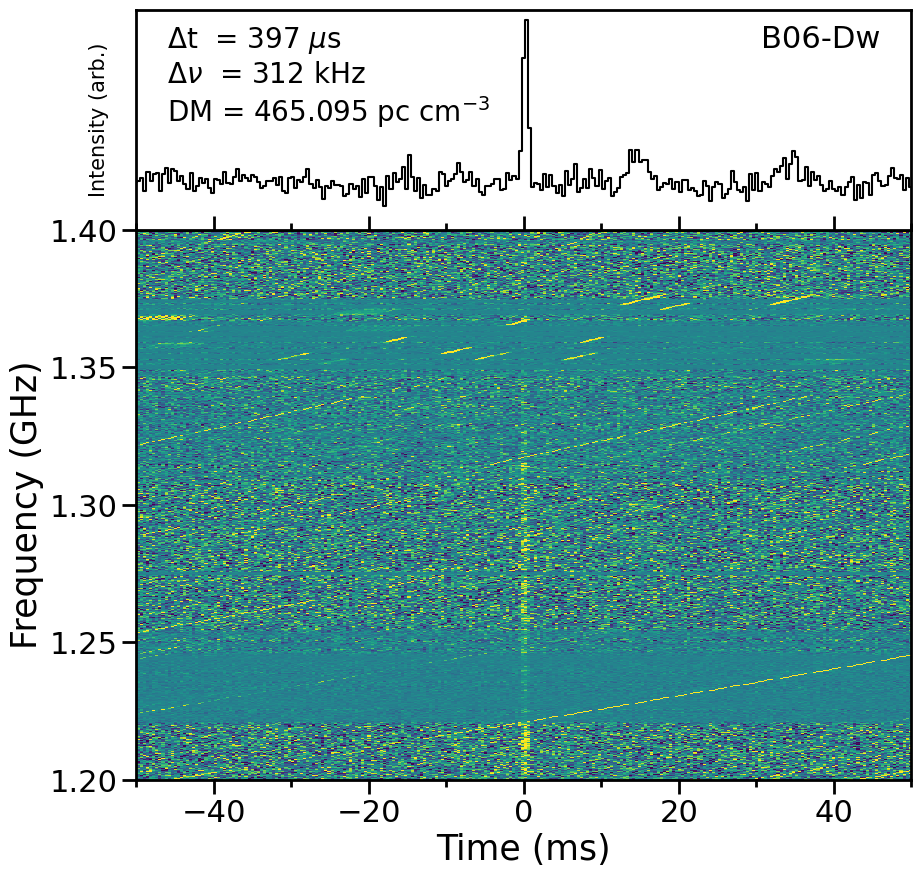

In [12]:
burst_list = ['/data1/omar/frb240619d/dwingeloo/FRB20240619D_L1_L2_spliced_2024_08_15_23_09_03_10sec_snippet.fil']
waterfaller_maker(burst=burst_list, DM=465.095, t_downsamp=2, f_downsamp=1, dededisp=None)